# Exercise 3: Embeddings as features for prediction

A take-home exercise. Exercises 1 and 2 used embeddings to compare texts with each other. Here they become ordinary predictors in an ordinary statistical model: we embed 1,200 tweets by US politicians, standardise the features, and train a penalised linear classifier to tell *partisan* tweets from *neutral* ones.

By the end you will have seen:
- the two-step recipe: embed, then fit any model you already know
- why the scaler must be fitted on the training set only
- how to tell a real result from chance with a permutation test, and how precise it is with a bootstrap

## Environment setup

Run the cell below.

In [1]:
import sys
if 'google.colab' in sys.modules:  # install packages when running on Google Colab
    !pip install sentence-transformers &> /dev/null

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifier, RidgeClassifierCV

DATA = "https://raw.githubusercontent.com/dwulff/LLM4BeSci_2025MetaRep/main/day_2/"
model = SentenceTransformer('all-MiniLM-L6-v2')

## 1. The data

Tweets with a label, *partisan* or *neutral*, already split into a training and a test set.

Run the cell below.

In [2]:
train = pd.read_csv(DATA + 'media_bias_train.csv')
test = pd.read_csv(DATA + 'media_bias_test.csv')
print(len(train), 'training tweets,', len(test), 'test tweets')
train[['text', 'bias']].head()

1200 training tweets, 100 test tweets


,text,bias
0,Excited to join @fairvote today @NYUWashington...,neutral
1,Placer reunirme c la directora de @NTN24 @CGur...,neutral
2,DID YOU KNOW: 73% of Americans want to #RaiseT...,neutral
3,.@meridianstar: http://t.co/gyjLbggc0t @GreggH...,neutral
4,".@AmericanLegion, @IAVA, @AMVETSNational, and ...",neutral


## 2. Embed, standardise, fit

Three steps. Embedding the 1,300 tweets takes about a minute on a CPU. The scaler is fitted on the training set only, so that nothing about the test set leaks into the model. The ridge classifier picks its penalty by cross-validation.

Run the cell below.

Train accuracy: 0.80
Test accuracy:  0.76   (chance = 0.50)


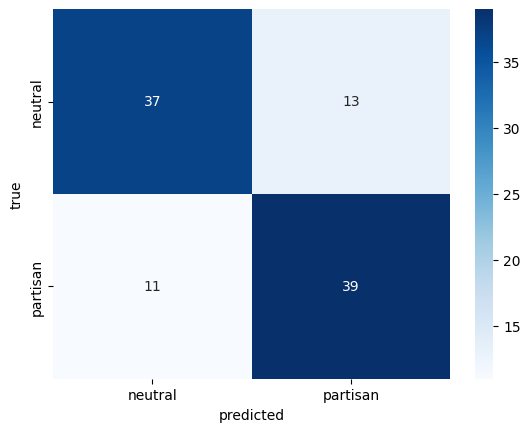

In [3]:
# 1. Embed
train_x = model.encode(train['text'])
test_x = model.encode(test['text'])

# 2. Standardise (fit on train only)
scaler = StandardScaler().fit(train_x)
train_x, test_x = scaler.transform(train_x), scaler.transform(test_x)

# 3. Fit a penalised linear classifier
ridge = RidgeClassifierCV(alphas=[1e-2, 1e-1, 1, 10, 100, 1000]).fit(train_x, train['bias'])

print(f"Train accuracy: {ridge.score(train_x, train['bias']):.2f}")
print(f"Test accuracy:  {ridge.score(test_x, test['bias']):.2f}   (chance = 0.50)")

confusion = pd.crosstab(test['bias'], ridge.predict(test_x), rownames=['true'], colnames=['predicted'])
sns.heatmap(confusion, annot=True, fmt='d', cmap='Blues');

**TASK 1**: Fit the scaler on the training and test set together (`StandardScaler().fit(np.vstack([train_x, test_x]))` before the transform). Does the test accuracy change? Why is this wrong even if it does not?

## 3. You versus the model

How hard is this judgement for a person? The cell below prints ten test tweets without labels. Write your guesses into `my_guesses` in the cell after it, and both of you are scored.

Run the cell below.

In [4]:
sample = test.sample(10, random_state=1)
for i, text in enumerate(sample['text']):
    print(f"{i}: {text}\n")

0: RT @WKBW Ohio Street Project Moves Forward http://t.co/T3vcwG8jZg

1: So what Dr. Lynch is saying is that the @DeptVetAffairs has the wrong goals. #LameExcuses #10 http://t.co/9iNMTfnW2a

2: Proud to receive @HDMAconnect's Bull Dog Award for my commitment to keeping our RX supply chain safe from counterfeit http://t.co/u9FSH4dlOt

3: @BarackObama's latest #Keystone delay hurts Montana jobs. No more excuses -- it's #TimeToBuild http://t.co/aEvKDFFwta

4: RT @AllDailyRepNews: Garamendi backs bills on flood rules, insurance rates http://t.co/AqGT69dw5F

5: New CBO report: increasing the minimum wage to $10.10 would raise wages for nearly 25 million Americans: http://t.co/2nlEv5y67S

6: The House will pass a bill to pay federal workers for their time in furlough once the shutdown ends.

7: I believe President Obama offered many common sense proposals to reducing gun violence. For example, background... http://t.co/g2xmO06E

8: .@TigernBham House DemsÛª #MakeItInAmerica plan is focused 

In [5]:
my_guesses = ['?', '?', '?', '?', '?', '?', '?', '?', '?', '?']   # <- 'partisan' or 'neutral', one per tweet above

truth = sample['bias'].values
scoreboard = pd.DataFrame({'tweet': sample['text'].str[:60].values, 'truth': truth, 'you': my_guesses, 'model': ridge.predict(test_x[sample.index])})
if '?' not in my_guesses:
    print(f"You:   {(scoreboard['you'] == truth).mean():.1f}")
print(f"Model: {(scoreboard['model'] == truth).mean():.1f}")
scoreboard

Model: 0.7


,tweet,truth,you,model
0,RT @WKBW Ohio Street Project Moves Forward htt...,partisan,?,partisan
1,So what Dr. Lynch is saying is that the @DeptV...,partisan,?,partisan
2,Proud to receive @HDMAconnect's Bull Dog Award...,neutral,?,neutral
3,@BarackObama's latest #Keystone delay hurts Mo...,partisan,?,partisan
4,RT @AllDailyRepNews: Garamendi backs bills on ...,partisan,?,partisan
5,New CBO report: increasing the minimum wage to...,neutral,?,partisan
6,The House will pass a bill to pay federal work...,neutral,?,partisan
7,I believe President Obama offered many common ...,partisan,?,partisan
8,.@TigernBham House DemsÛª #MakeItInAmerica pl...,partisan,?,partisan
9,Typical #SNAP household with kids has income o...,partisan,?,neutral


## 4. Is .76 real, and how precise is it?

Two questions, two resampling answers. The permutation test refits the classifier on shuffled labels to show what chance produces. The bootstrap resamples the test set to give a confidence interval around the observed accuracy.

Run the cell below.

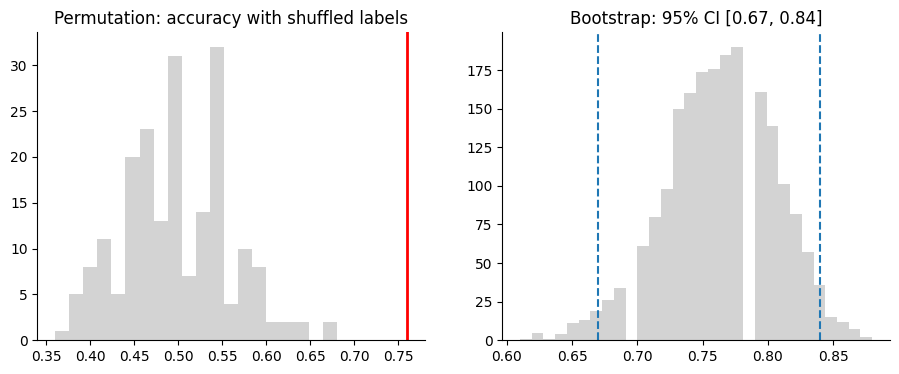

In [6]:
rng = np.random.default_rng(0)
observed_accuracy = ridge.score(test_x, test['bias'])

# Permutation: shuffle the training labels, refit, score on the real test labels
null_accuracy = [RidgeClassifier(alpha=ridge.alpha_).fit(train_x, rng.permutation(train['bias'].values)).score(test_x, test['bias'])
                 for _ in range(200)]

# Bootstrap: resample the test set with replacement
correct = ridge.predict(test_x) == test['bias'].values
boot_accuracy = [rng.choice(correct, size=len(correct)).mean() for _ in range(2000)]
ci_low, ci_high = np.percentile(boot_accuracy, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(null_accuracy, bins=20, color='lightgrey'); axes[0].axvline(observed_accuracy, color='red', linewidth=2)
axes[0].set_title('Permutation: accuracy with shuffled labels')
axes[1].hist(boot_accuracy, bins=30, color='lightgrey'); axes[1].axvline(ci_low, linestyle='--'); axes[1].axvline(ci_high, linestyle='--')
axes[1].set_title(f'Bootstrap: 95% CI [{ci_low:.2f}, {ci_high:.2f}]')
sns.despine()

**TASK 2**: The interval is wide because the test set has 100 tweets. Move 400 tweets from `train` to `test` in section 1 and rerun. Which changed more, the interval or the point estimate?

**TASK 3**: Replace `RidgeClassifierCV` with `sklearn.linear_model.LogisticRegressionCV` or `sklearn.ensemble.RandomForestClassifier`. Does the classical model matter as much as the embedding model?

**BONUS TASK**: Open the [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard), pick a well-ranked model under 1B parameters with the `sentence-transformers` tag, put its name into the setup cell and rerun. Does a bigger embedding model help?

## 5. How much labelled data do you need?

The practical question for your own study. The cell below refits the classifier on random subsets of the training set and plots test accuracy against training size.

Run the cell below.

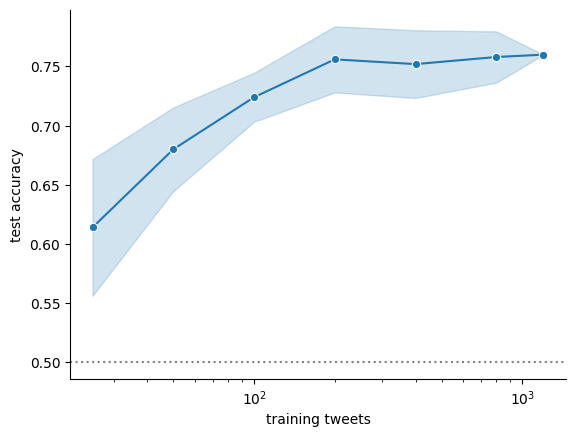

In [7]:
curve = []
for n in [25, 50, 100, 200, 400, 800, len(train)]:
    for rep in range(5):
        idx = rng.choice(len(train), size=n, replace=False)
        acc = RidgeClassifier(alpha=ridge.alpha_).fit(train_x[idx], train['bias'].values[idx]).score(test_x, test['bias'])
        curve.append({'training tweets': n, 'test accuracy': acc})

sns.lineplot(data=pd.DataFrame(curve), x='training tweets', y='test accuracy', marker='o', errorbar='sd')
plt.xscale('log'); plt.axhline(0.5, color='grey', linestyle=':'); sns.despine()

**TASK 4**: Where does the curve flatten? If each label costs a minute of a rater's time, how many would you buy?